# KKN Radar → Lean Polar Volumes for Doppler, PyTDA and Hydrometeor Classification (Data Preparation, Repo 2)

**Notebook นี้คือ "ที่มา" ของข้อมูลใน `data/` ของ repo สาธิต Doppler · PyTDA · HID**
อ่านไฟล์ UF ของเรดาร์ขอนแก่น (KKN) → QC แบบ gentle (ชุดเดียวกับ notebook ของ repo pysteps) → เขียน **CfRadial แบบ polar ขนาดเล็ก** (int16 + zlib) ที่เก็บเฉพาะตัวแปรที่ต้องใช้

| ตัวแปรในไฟล์ | ความละเอียดที่เก็บ | ใช้ในบทเรียน |
|---|---|---|
| `reflectivity_raw` (ยังไม่ QC) | 0.1 dBZ | เปรียบเทียบก่อน/หลัง QC |
| `reflectivity_qc` | 0.1 dBZ | ทุกบท, PyTDA |
| `velocity_qc` (**ยังไม่ dealias**) | 0.1 m/s | Doppler: ให้นิสิตเห็น aliasing และ dealias เอง |
| `spectrum_width_qc` | 0.1 m/s | PyTDA (EDR) |
| `differential_reflectivity_qc` | 0.01 dB | KDP/attenuation → HID |
| `differential_phase_qc` (ไม่กรอง texture) | 0.1° | คำนวณ KDP |
| `cross_correlation_ratio_qc` | 0.001 | HID |
| `qc_flag` (uint8 bitmask) | – | เหตุผลที่ gate ถูกตัด |

ไม่เก็บ height/temperature ราย gate (คำนวณใหม่ได้ทันที) — เก็บ **sounding** แยกใน `data/sounding/` และระดับ 0/−10/−20 °C ใน metadata

| ส่วน | ทำอะไร |
|---|---|
| **BASE** | 1 volume ทีละขั้น + อ่านกลับตรวจความถูกต้อง + ภาพตีพิมพ์ |
| **BATCH** | ทั้งวัน (92 ไฟล์) → เก็บครบใน `_work/` → เลือกช่วงพีคอัตโนมัติ (6–8 volume) คัดลอกเข้า repo |

In [1]:
# ================================================================
# CELL 0: Install packages and mount Google Drive
# ================================================================
!pip -q install arm_pyart cmweather cartopy geopandas netCDF4 xarray pyproj

from google.colab import drive
drive.mount("/content/drive")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.8/14.8 MB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 28.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 42.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.8/157.8 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.6/102.6 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 31.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the sour

## 1. CONFIG

In [2]:
# ================================================================
# CELL 1: Imports and configuration
# ================================================================
import os, re, io, bz2, gzip, json, shutil, tempfile, datetime, warnings, traceback
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import requests
from PIL import Image
import netCDF4
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from matplotlib.colors import LightSource
from scipy.ndimage import binary_dilation, uniform_filter1d, map_coordinates
from scipy.ndimage import label as cc_label
import geopandas as gpd
from shapely.geometry import box, Point
from shapely.ops import transform as shp_transform
from pyproj import Transformer
import cartopy.crs as ccrs
import cartopy.io.shapereader as cshp
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

warnings.filterwarnings("ignore")
import pyart
try:
    import cmweather  # registers ChaseSpectral, HomeyerRainbow, balance, ...
except Exception:
    pass

PREP_VERSION = "kkn-prep-1.0.0"

# ---------------- paths ----------------
ROOT = Path("/content/drive/MyDrive/000_research/08Storm_NorthEast_FF69")
RADAR_NAME = "KKN"
CASE_DATE = "20240503"            # YYYYMMDD (UTC)
RAW_DATE_FOLDER = "240503"        # YYMMDD folder of raw UF files
RAW_DIR = ROOT / "0data" / "1radar" / RADAR_NAME / RAW_DATE_FOLDER
RAW_PATTERN = f"{RADAR_NAME}240@{CASE_DATE}*.uf.bz2"
SOUNDING_FILE = (ROOT / "0data" / "0downloaded_sounding" / "year_2024" /
                 "sounding_48431_2024-05-03_00Z.csv")

OUT_BASE = ROOT / "2output" / "Github_Pysteps_Data_prepare"
REPO_DIR = OUT_BASE / "repo2_kkn_radar_dualpol"            # mirror of the GitHub repo
DATA_DIR = REPO_DIR / "data" / f"{RADAR_NAME}_{CASE_DATE}"
POLAR_DIR = DATA_DIR / "polar"                             # selected volumes only
SOUNDING_DIR = REPO_DIR / "data" / "sounding"
BASEMAP_DIR = REPO_DIR / "data" / "basemap"
FIG_DIR = REPO_DIR / "figures"
WORK_DIR = OUT_BASE / "_work" / "repo2_polar"              # all volumes; NOT uploaded

# ---------------- base (single-volume) run ----------------
SINGLE_TIME = "20240503_1000"
PLOT_SWEEP = 0

# ---------------- gentle base-QC (same thresholds as Level-1) ----------------
ZH_ECHO_FLOOR_DBZ = 0.0
NONMET_RHOHV_MAX = 0.70
NONMET_ZH_MAX_DBZ = 25.0
SPECKLE_MIN_GATES = 12
FLARE_MIN_LEN_KM = 120.0
FLARE_ZH_MIN_DBZ = 5.0
FLARE_RHOHV_MEAN_MAX = 0.75
FLARE_VELVALID_MAX = 0.30
FLARE_PROTECT_DBZ = 45.0
FLARE_PROTECT_FRAC = 0.03
SW_MAX = 12.0
QC_SD_PHIDP_W = 5
QC_SD_PHIDP_MAX = 20.0

# ---------------- lean file: name -> (source key, base metadata, scale) ----------------
# Packing as int16 with these scale factors keeps far more precision than the
# measurement accuracy while letting zlib compress the file 5-10x.
POLAR_SPECS = {
    "reflectivity_raw":             ("REFL_RAW", "reflectivity", 0.1),
    "reflectivity_qc":              ("reflectivity_qc", "reflectivity", 0.1),
    "velocity_qc":                  ("velocity_qc", "velocity", 0.1),
    "spectrum_width_qc":            ("spectrum_width_qc", "spectrum_width", 0.1),
    "differential_reflectivity_qc": ("ZDR_QC", "differential_reflectivity", 0.01),
    "differential_phase_qc":        ("PHIDP_QC", "differential_phase", 0.1),
    "cross_correlation_ratio_qc":   ("RHO_QC", "cross_correlation_ratio", 0.001),
}

# ---------------- batch / subset for GitHub ----------------
SKIP_EXISTING = True
MAX_VOLUMES = None                # e.g. 3 for a quick test
PEAK_N_VOLUMES = 8                # consecutive volumes copied into the repo
REPO2_TIMES = None                # e.g. ["20240503_0930", ...]; None = automatic peak window
PEAK_DBZ = 40.0                   # echo-area threshold used to find the peak

# ---------------- figures / cartography ----------------
PUB_MODE = True
SHOW_FIGURES = True
FIG_DPI = 300
SLOT_MINUTES = 15
LT_OFFSET_H = 7
RANGE_MAX_KM = 240.0
MAP_HALF_KM = 255.0
RANGE_RINGS_KM = [60, 120, 180, 240]
RING_LABEL_AZ = 40.0
BOUNDARY_COUNTRIES = ["THA", "LAO", "KHM", "VNM"]
COVERAGE_BG = "#f1f1f1"
WATER_FILL = "#dbe9f4"
WATER_LINE = "#6b8fb3"
TERRAIN_VMAX_M = 1400.0
REFL_LEVELS = np.arange(0, 75, 5)
ZOOM_HALF_KM = None               # e.g. 150 to zoom multi-panel figures on the storm; None = full 255 km

for d in [POLAR_DIR, SOUNDING_DIR, BASEMAP_DIR, FIG_DIR, WORK_DIR / "polar_all", WORK_DIR / "logs"]:
    d.mkdir(parents=True, exist_ok=True)

print("Py-ART", pyart.__version__, "|", PREP_VERSION)
print("RAW_DIR :", RAW_DIR, "| exists:", RAW_DIR.exists())
print("REPO_DIR:", REPO_DIR)


## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly supported
## by the U.S. Department of Energy Office of Science as part of
## the Atmospheric Radiation Measurement (ARM) User Facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119

Py-ART 2.3.0 | kkn-prep-1.0.0
RAW_DIR : /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN/240503 | exists: True
REPO_DIR: /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/2output/Github_Pysteps_Data_prepare/repo2_kkn_radar_dualpol


## 2. Functions
### 2.1 อ่านไฟล์และ QC พื้นฐาน (ชุดเดียวกับ notebook ของ repo pysteps)

In [3]:
# ================================================================
# COMMON FUNCTIONS (A): FILE DISCOVERY, RADAR READER, GENTLE BASE-QC
# This block is identical in both data-preparation notebooks
# (repo 1: pysteps, repo 2: Doppler / PyTDA / HID).
# ================================================================

def parse_time_tag(path):
    """KKN240@202405031000.uf.bz2 -> '20240503_1000' (UTC)."""
    m = re.search(rf"{RADAR_NAME}240@(\d{{8}})(\d{{4}})\.uf(\.bz2|\.gz)?$", Path(path).name)
    return f"{m.group(1)}_{m.group(2)}" if m else None


def tag_to_datetime(time_tag):
    return datetime.datetime.strptime(time_tag, "%Y%m%d_%H%M")


def time_label(dt, with_date=True):
    """'03 May 2024 10:00 UTC (17:00 LT)'"""
    lt = dt + datetime.timedelta(hours=LT_OFFSET_H)
    d = dt.strftime("%d %b %Y ") if with_date else ""
    return f"{d}{dt:%H:%M} UTC ({lt:%H:%M} LT)"


def discover_raw_files():
    """Return a DataFrame of raw files found for the case day, sorted by time."""
    rows = []
    for f in sorted(RAW_DIR.glob(RAW_PATTERN)):
        tag = parse_time_tag(f)
        if tag is not None:
            rows.append({"time_tag": tag, "raw_file": str(f),
                         "size_MB": round(f.stat().st_size / 1e6, 2)})
    return pd.DataFrame(rows, columns=["time_tag", "raw_file", "size_MB"])


def expected_slots():
    """Regular UTC time slots for the case day (every SLOT_MINUTES)."""
    t0 = datetime.datetime.strptime(CASE_DATE, "%Y%m%d")
    n = int(24 * 60 / SLOT_MINUTES)
    return [t0 + datetime.timedelta(minutes=SLOT_MINUTES * i) for i in range(n)]


def build_inventory():
    """Compare expected slots with files that exist -> inventory DataFrame."""
    found = discover_raw_files()
    found_map = dict(zip(found["time_tag"], found["raw_file"]))
    rows = []
    for dt in expected_slots():
        tag = dt.strftime("%Y%m%d_%H%M")
        rows.append({"time_tag": tag, "time_utc": dt,
                     "raw_file": found_map.get(tag, ""),
                     "exists": tag in found_map})
    inv = pd.DataFrame(rows)
    off_grid = sorted(set(found_map) - set(inv["time_tag"]))
    if off_grid:
        print("WARNING: files not on the regular time grid (ignored):", off_grid)
    return inv


def read_radar_magic(path, verbose=True):
    """
    Robust KKN reader. Do not trust the extension: TMD '.uf.bz2' files are
    often gzip streams. Detect the compression from the magic bytes.
    """
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    with open(path, "rb") as f:
        magic = f.read(4)

    tmp = tempfile.NamedTemporaryFile(suffix=".uf", delete=False)
    tmp_path = tmp.name
    tmp.close()
    try:
        if magic[:3] == b"BZh":
            opener, kind = bz2.open, "bzip2"
        elif magic[:2] == b"\x1f\x8b":
            opener, kind = gzip.open, "gzip"
        else:
            opener, kind = None, "uncompressed"

        if opener is None:
            read_path = str(path)
        else:
            with opener(path, "rb") as fin, open(tmp_path, "wb") as fout:
                shutil.copyfileobj(fin, fout)
            read_path = tmp_path

        try:
            radar = pyart.io.read(read_path)
        except Exception:
            radar = pyart.io.read_uf(read_path)
    finally:
        if os.path.exists(tmp_path):
            os.unlink(tmp_path)

    if verbose:
        print(f"Read {path.name}  [{kind} stream]")
    return radar


def pick_field(radar, candidates):
    for c in candidates:
        if c in radar.fields:
            return c
    return None


def farr(radar, field):
    """Field -> float32 ndarray with NaN for masked gates (None if missing)."""
    if field is None or field not in radar.fields:
        return None
    return np.ma.filled(radar.fields[field]["data"].astype(np.float32), np.nan)


def detect_fields(radar):
    f = {
        "REFL": pick_field(radar, ["corrected_reflectivity", "reflectivity"]),
        "VEL": pick_field(radar, ["velocity"]),
        "SW": pick_field(radar, ["spectrum_width"]),
        "ZDR": pick_field(radar, ["corrected_differential_reflectivity",
                                   "differential_reflectivity"]),
        "PHIDP": pick_field(radar, ["differential_phase"]),
        "RHO": pick_field(radar, ["cross_correlation_ratio"]),
    }
    if f["REFL"] is None:
        raise ValueError(f"No reflectivity field. Available: {list(radar.fields)}")
    return f


def radar_start_time(radar):
    """Volume start time as a plain datetime (Py-ART may return cftime)."""
    t = pyart.util.datetime_from_radar(radar)
    return datetime.datetime(t.year, t.month, t.day, t.hour, t.minute, int(t.second))


def get_nyquist(radar):
    try:
        v = np.asarray(radar.instrument_parameters["nyquist_velocity"]["data"], float)
        v = v[np.isfinite(v) & (v > 0)]
        return float(np.nanmedian(v)) if v.size else np.nan
    except Exception:
        return np.nan


def sweep_index_1d(radar):
    swp = np.zeros(radar.nrays, dtype=np.int16)
    for k in range(radar.nsweeps):
        a = int(radar.sweep_start_ray_index["data"][k])
        b = int(radar.sweep_end_ray_index["data"][k])
        swp[a:b + 1] = k
    return swp


def radar_inventory(radar, fields):
    """Print the facts a radar meteorologist checks first."""
    lat0 = float(radar.latitude["data"][0]); lon0 = float(radar.longitude["data"][0])
    rng = radar.range["data"]
    print(f"  time (volume start) : {radar_start_time(radar):%Y-%m-%d %H:%M:%S} UTC")
    print(f"  location            : {lat0:.4f} N, {lon0:.4f} E, {float(radar.altitude['data'][0]):.0f} m MSL")
    print(f"  sweeps/rays/gates   : {radar.nsweeps} / {radar.nrays} / {radar.ngates}")
    print(f"  elevations (deg)    : {np.round(radar.fixed_angle['data'], 2).tolist()}")
    print(f"  range               : {rng[0]/1e3:.2f}-{rng[-1]/1e3:.1f} km, gate {np.median(np.diff(rng)):.0f} m")
    print(f"  Nyquist velocity    : {get_nyquist(radar):.2f} m/s")
    print(f"  fields used         : {fields}")


# ---------------- gentle base-QC (algorithm kept from Level-1 codebase) ----

def find_flare_rays(radar, zh, rho, vel_finite):
    """Conservative flare-ray (sun spike / interference) detector, per ray."""
    dr_km = float(np.nanmedian(np.diff(radar.range["data"])) / 1000.0)
    min_gate_count = int(FLARE_MIN_LEN_KM / max(dr_km, 0.1))
    valid = np.isfinite(zh) & (zh > FLARE_ZH_MIN_DBZ)
    spike = np.zeros(radar.nrays, dtype=bool)
    for i in range(radar.nrays):
        v = valid[i]
        if v.sum() < min_gate_count:
            continue
        if np.mean(zh[i][v] >= FLARE_PROTECT_DBZ) >= FLARE_PROTECT_FRAC:
            continue                                  # protect real convective cores
        rho_ok = True if rho is None else np.nanmean(rho[i][v]) <= FLARE_RHOHV_MEAN_MAX
        vel_ok = True if vel_finite is None else np.mean(vel_finite[i][v]) <= FLARE_VELVALID_MAX
        spike[i] = rho_ok and vel_ok
    return spike, binary_dilation(spike, iterations=1)


def remove_speckles_polar(mask_keep, radar, min_gates=12, pad=8):
    """Remove connected components < min_gates in each sweep (azimuth wraps)."""
    keep = mask_keep.copy()
    removed = np.zeros_like(keep, dtype=bool)
    swp = sweep_index_1d(radar)
    structure = np.ones((3, 3), dtype=np.int8)
    for k in range(radar.nsweeps):
        ridx = np.where(swp == k)[0]
        if len(ridx) == 0:
            continue
        sub = keep[ridx, :].copy()
        if len(ridx) > 2 * pad:
            padded = np.vstack([sub[-pad:], sub, sub[:pad]])
            lab_p, _ = cc_label(padded, structure=structure)
            sizes = np.bincount(lab_p.ravel())
            lab = lab_p[pad:pad + len(ridx), :]
        else:
            lab, _ = cc_label(sub, structure=structure)
            sizes = np.bincount(lab.ravel())
        small = np.isin(lab, np.where(sizes < min_gates)[0]) & (lab > 0)
        sub[small] = False
        keep[ridx, :] = sub
        removed[ridx, :] = small
    return keep, removed


def circular_sd_deg_range(data_deg, window=5):
    """Circular standard deviation of an angle (PhiDP) along range."""
    x = np.asarray(data_deg, dtype=float)
    valid = np.isfinite(x)
    a = np.deg2rad(np.where(valid, x, 0.0))
    cnt = uniform_filter1d(valid.astype(float), window, axis=1, mode="nearest") * window
    s = uniform_filter1d(np.where(valid, np.sin(a), 0), window, axis=1, mode="nearest") * window
    c = uniform_filter1d(np.where(valid, np.cos(a), 0), window, axis=1, mode="nearest") * window
    with np.errstate(invalid="ignore", divide="ignore"):
        R = np.clip(np.hypot(s / cnt, c / cnt), 1e-6, 1.0)
        sd = np.rad2deg(np.sqrt(-2.0 * np.log(R)))
    sd[cnt < 3] = np.nan
    return sd.astype(np.float32)


# qc_flag bit convention (uint8). A gate keeps reflectivity if (qc_flag & 15) == 0.
QC_BITS = {
    "no_echo_or_below_floor": 1,
    "flare_ray": 2,
    "nonmet_low_rhohv_weak_z": 4,
    "speckle": 8,
    "spectrum_width_invalid": 16,
    "velocity_invalid": 32,
    "phidp_texture_high": 64,
}


def gentle_base_qc(radar, fields, verbose=True):
    """
    Gentle, reflectivity-preserving base-QC.
      keep  = ZH >= floor  AND not flare ray  AND not (low rhoHV & weak ZH)
              AND not a small speckle
    Returns a dict with QC arrays, masks, qc_flag and gate counts.
    """
    zh = farr(radar, fields["REFL"])
    rho = farr(radar, fields["RHO"])
    vel = farr(radar, fields["VEL"])
    sw = farr(radar, fields["SW"])
    phidp = farr(radar, fields["PHIDP"])
    vel_finite = None if vel is None else np.isfinite(vel)

    echo = np.isfinite(zh) & (zh >= ZH_ECHO_FLOOR_DBZ)
    flare_raw, flare_dil = find_flare_rays(radar, zh, rho, vel_finite)
    flare = np.zeros_like(echo)
    flare[flare_dil, :] = True

    if rho is not None:
        nonmet = (echo & ~flare & np.isfinite(rho)
                  & (rho < NONMET_RHOHV_MAX) & (zh < NONMET_ZH_MAX_DBZ))
    else:
        nonmet = np.zeros_like(echo)

    keep, speckle = remove_speckles_polar(echo & ~flare & ~nonmet, radar,
                                          min_gates=SPECKLE_MIN_GATES)

    out = {"zh_raw": zh, "keep": keep,
           "reflectivity_qc": np.where(keep, zh, np.nan).astype(np.float32)}

    flag = np.zeros(zh.shape, dtype=np.uint8)
    flag[~echo] |= QC_BITS["no_echo_or_below_floor"]
    flag[flare] |= QC_BITS["flare_ray"]
    flag[nonmet] |= QC_BITS["nonmet_low_rhohv_weak_z"]
    flag[speckle] |= QC_BITS["speckle"]

    if vel is not None:
        vel_valid = keep & np.isfinite(vel)
        out["velocity_qc"] = np.where(vel_valid, vel, np.nan).astype(np.float32)
        flag[keep & ~vel_valid] |= QC_BITS["velocity_invalid"]
    if sw is not None:
        sw_valid = keep & np.isfinite(sw) & (sw >= 0.0) & (sw <= SW_MAX)
        out["spectrum_width_qc"] = np.where(sw_valid, sw, np.nan).astype(np.float32)
        flag[keep & ~sw_valid] |= QC_BITS["spectrum_width_invalid"]
    if phidp is not None:
        tex = circular_sd_deg_range(phidp, window=QC_SD_PHIDP_W)
        phase_ok = np.isfinite(phidp) & (tex < QC_SD_PHIDP_MAX)
        flag[keep & ~phase_ok] |= QC_BITS["phidp_texture_high"]
    out["qc_flag"] = flag

    n_raw = int(np.isfinite(zh).sum())
    out["counts"] = {
        "raw_finite": n_raw,
        "echo_floor": int(echo.sum()),
        "flare_rays": int(flare_dil.sum()),
        "nonmet_removed": int(nonmet.sum()),
        "speckle_removed": int(speckle.sum()),
        "kept": int(keep.sum()),
        "kept_pct_of_raw": round(100.0 * keep.sum() / max(n_raw, 1), 2),
    }
    if verbose:
        for k, v in out["counts"].items():
            print(f"  {k:<18}: {v}")
    return out

### 2.2 Sounding และไฟล์ polar ขนาดเล็ก

In [4]:
# ================================================================
# SOUNDING + LEAN POLAR CFRADIAL
# ================================================================

def sounding_isotherms(sounding_file, levels=(0.0, -10.0, -20.0)):
    """Height (m MSL) where temperature first drops below each level."""
    out = {}
    try:
        df = pd.read_csv(sounding_file)
        h = pd.to_numeric(df["height"], errors="coerce").values
        t = pd.to_numeric(df["temperature"], errors="coerce").values
        m = np.isfinite(h) & np.isfinite(t)
        h, t = h[m], t[m]
        o = np.argsort(h)
        h, t = h[o], t[o]
        for lev in levels:
            idx = np.where((t[:-1] >= lev) & (t[1:] < lev))[0]
            if idx.size:
                i = idx[0]
                out[f"height_{int(lev)}C_m_msl"] = float(h[i] + (lev - t[i]) * (h[i + 1] - h[i]) / (t[i + 1] - t[i]))
    except Exception as e:
        print("Sounding not usable:", e)
    return out


def packed_field(data, base_name, long_name, scale, chunks):
    """Py-ART field dict that is written as int16 * scale_factor with zlib."""
    f = pyart.config.get_metadata(base_name)
    f.pop("valid_min", None); f.pop("valid_max", None)
    f.update({
        "data": np.ma.masked_invalid(np.asarray(data, np.float32)),
        "long_name": long_name,
        "_Write_as_dtype": "int16",
        "scale_factor": np.float32(scale), "add_offset": np.float32(0.0),
        "_FillValue": np.int16(-32768),
        "_DeflateLevel": 4, "_Shuffle": True, "_ChunkSizes": chunks,
    })
    return f


def write_lean_polar(radar, fields, qc, out_path, isotherms):
    """Add the packed fields to the radar object and write only those."""
    keep = qc["keep"]
    src = {
        "REFL_RAW": qc["zh_raw"],
        "reflectivity_qc": qc["reflectivity_qc"],
        "velocity_qc": qc.get("velocity_qc"),
        "spectrum_width_qc": qc.get("spectrum_width_qc"),
        "ZDR_QC": None if fields["ZDR"] is None else np.where(keep, farr(radar, fields["ZDR"]), np.nan),
        "PHIDP_QC": None if fields["PHIDP"] is None else np.where(keep, farr(radar, fields["PHIDP"]), np.nan),
        "RHO_QC": None if fields["RHO"] is None else np.where(keep, farr(radar, fields["RHO"]), np.nan),
    }
    long = {
        "reflectivity_raw": f"reflectivity before base-QC (source field: {fields['REFL']})",
        "reflectivity_qc": "reflectivity after gentle base-QC",
        "velocity_qc": "radial velocity after base-QC, NOT dealiased",
        "spectrum_width_qc": f"spectrum width after base-QC (0-{SW_MAX} m/s)",
        "differential_reflectivity_qc": f"ZDR within base-QC mask, no bias correction (source: {fields['ZDR']})",
        "differential_phase_qc": "PhiDP within base-QC mask, no unfolding/filtering",
        "cross_correlation_ratio_qc": "rhoHV within base-QC mask",
    }
    # one HDF5 chunk per sweep (default would be one per ray -> large index overhead)
    chunks = (int(np.max(radar.rays_per_sweep["data"])), radar.ngates)
    written = []
    for name, (key, base, scale) in POLAR_SPECS.items():
        if src.get(key) is None:
            print(f"  skip {name}: source field not available")
            continue
        radar.add_field(name, packed_field(src[key], base, long[name], scale, chunks), replace_existing=True)
        written.append(name)

    radar.add_field("qc_flag", {
        "data": qc["qc_flag"].astype(np.uint8),
        "units": "1", "long_name": "base-QC flag (bitmask)",
        "flag_masks": np.array(list(QC_BITS.values()), np.uint8),
        "flag_meanings": " ".join(QC_BITS.keys()),
        "comment": "reflectivity kept where (qc_flag & 15) == 0",
        "_DeflateLevel": 4, "_Shuffle": True, "_ChunkSizes": chunks,
    }, replace_existing=True)
    written.append("qc_flag")

    radar.metadata.update({
        "title": f"{RADAR_NAME} lean polar volume (gentle base-QC) for Doppler / PyTDA / HID teaching",
        "processing_code": PREP_VERSION,
        "qc_strategy": (f"keep ZH>={ZH_ECHO_FLOOR_DBZ} dBZ; remove flare rays; remove rhoHV<{NONMET_RHOHV_MAX} "
                        f"with ZH<{NONMET_ZH_MAX_DBZ} dBZ; remove speckles <{SPECKLE_MIN_GATES} gates"),
        "velocity_note": f"velocity is NOT dealiased; Nyquist = {get_nyquist(radar):.2f} m/s",
        "dualpol_note": "no ZDR bias correction, no PhiDP processing, no attenuation correction",
        "height_temperature_note": "compute gate heights from range/elevation; temperature from data/sounding",
        "sounding_file": Path(SOUNDING_FILE).name,
        **{k: f"{v:.0f}" for k, v in isotherms.items()},
        "history": f"created {datetime.datetime.utcnow():%Y-%m-%dT%H:%M:%SZ}",
    })
    tmp = str(out_path) + ".tmp"
    pyart.io.write_cfradial(tmp, radar, include_fields=written)
    os.replace(tmp, out_path)
    return written


def check_lean_file(path, qc):
    """Read back and confirm packing kept the QC result."""
    r = pyart.io.read_cfradial(str(path))
    z = np.ma.filled(r.fields["reflectivity_qc"]["data"].astype(float), np.nan)
    same = int(np.isfinite(z).sum()) == int(np.isfinite(qc["reflectivity_qc"]).sum())
    dmax = float(np.nanmax(np.abs(z - qc["reflectivity_qc"])))
    with netCDF4.Dataset(path) as nc:
        dtypes = {v: str(nc[v].dtype) for v in ["reflectivity_qc", "velocity_qc", "qc_flag"] if v in nc.variables}
    print(f"  fields: {list(r.fields)}")
    print(f"  stored dtypes: {dtypes}")
    print(f"  same number of QC gates: {same} | max |ΔZ| after packing: {dmax:.3f} dB")
    return r


def gate_area_km2(radar, sweep):
    sl = radar.get_slice(sweep)
    r = radar.range["data"].astype(float) / 1e3
    dr = float(np.median(np.diff(r)))
    az = np.sort(radar.azimuth["data"][sl].astype(float))
    daz = np.deg2rad(float(np.median(np.diff(az))))
    return np.broadcast_to(r * dr * daz, (sl.stop - sl.start, r.size))


def sweep_echo_stats(radar, zqc, sweep=0):
    a = gate_area_km2(radar, sweep)
    z = zqc[radar.get_slice(sweep)]
    out = {f"area_ge{t}_km2_sweep{sweep}": float(np.nansum(np.where(z >= t, a, 0.0)))
           for t in (20, 30, 40, 50)}
    out["max_dbz"] = float(np.nanmax(z)) if np.isfinite(z).any() else np.nan
    return out

### 2.3 รูปแบบภาพ แผนที่ และขอบเขตการปกครอง (ชุดเดียวกับ notebook ของ repo pysteps)

In [5]:
# ================================================================
# COMMON FUNCTIONS (B): PUBLICATION STYLE, BASEMAP DATA, MAP DRAWING
# This block is identical in both data-preparation notebooks.
# ================================================================

MM = 1 / 25.4                     # inch per mm
FIG_W_SINGLE = 85 * MM            # journal single column
FIG_W_ONEHALF = 140 * MM
FIG_W_DOUBLE = 174 * MM           # journal double column


def set_pub_style():
    sans = ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"]
    plt.rcParams.update({
        "font.family": "sans-serif", "font.sans-serif": sans,
        "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
        "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
        "axes.linewidth": 0.6, "lines.linewidth": 0.9,
        "xtick.major.width": 0.6, "ytick.major.width": 0.6,
        "xtick.major.size": 2.5, "ytick.major.size": 2.5,
        "xtick.direction": "out", "ytick.direction": "out",
        "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.03,
        "pdf.fonttype": 42, "ps.fonttype": 42,       # embed TrueType (journal requirement)
        "figure.dpi": 110,
    })


def save_figure(fig, name):
    """Save PDF (vector text, rasterized data) + PNG 300 dpi into FIG_DIR."""
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    out = []
    for ext in ("pdf", "png"):
        p = FIG_DIR / f"{name}.{ext}"
        fig.savefig(p, dpi=FIG_DPI)
        out.append(p)
    print("Saved:", ", ".join(f"{p.name} ({p.stat().st_size/1e6:.2f} MB)" for p in out))
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)
    return out


def get_cmap_safe(names, fallback="turbo"):
    for n in ([names] if isinstance(names, str) else names):
        try:
            return mpl.colormaps[n]
        except Exception:
            continue
    return mpl.colormaps[fallback]


def discrete_cmap_norm(names, levels, design_range=None, extend="max", fallback="turbo"):
    """Sample a (continuous) colormap into len(levels)-1 discrete colours."""
    base = get_cmap_safe(names, fallback)
    lo, hi = design_range if design_range else (levels[0], levels[-1])
    pos = (np.asarray(levels[:-1]) + np.diff(levels) / 2 - lo) / (hi - lo)
    cmap = mcolors.ListedColormap(base(np.clip(pos, 0, 1)))
    if extend in ("max", "both"):
        cmap.set_over(base(min(1.0, (levels[-1] + np.diff(levels)[-1] - lo) / (hi - lo))))
    if extend in ("min", "both"):
        cmap.set_under(base(max(0.0, (levels[0] - np.diff(levels)[0] - lo) / (hi - lo))))
    cmap.set_bad((0, 0, 0, 0))
    return cmap, mcolors.BoundaryNorm(levels, cmap.N)


def refl_cmap_norm():
    # ChaseSpectral / HomeyerRainbow are colour-vision-deficiency friendly
    # radar scales (designed over about -10..80 dBZ); 5-dBZ classes from 0 dBZ.
    return discrete_cmap_norm(["ChaseSpectral", "HomeyerRainbow", "pyart_HomeyerRainbow"],
                              REFL_LEVELS, design_range=(-10, 80))


# ---------------- map projection ----------------

def map_projection(lon0, lat0):
    """Azimuthal equidistant centred on the radar: range rings are true circles."""
    return ccrs.AzimuthalEquidistant(central_longitude=lon0, central_latitude=lat0)


def aeqd_proj4(lon0, lat0):
    return (f"+proj=aeqd +lat_0={lat0:.6f} +lon_0={lon0:.6f} +x_0=0 +y_0=0 "
            f"+datum=WGS84 +units=m +no_defs")


def domain_lonlat_bbox(lon0, lat0, half_km):
    tr = Transformer.from_crs(aeqd_proj4(lon0, lat0), "EPSG:4326", always_xy=True)
    t = np.linspace(-1, 1, 41) * half_km * 1e3
    xx = np.concatenate([t, t, np.full_like(t, t[0]), np.full_like(t, t[-1])])
    yy = np.concatenate([np.full_like(t, t[0]), np.full_like(t, t[-1]), t, t])
    lon, lat = tr.transform(xx, yy)
    return float(lon.min()), float(lat.min()), float(lon.max()), float(lat.max())


# ---------------- administrative boundaries (geoBoundaries, CC BY 4.0) ----

def _download_geoboundaries(iso, adm):
    """Download a simplified geoBoundaries layer (gbOpen, CC BY 4.0)."""
    urls = []
    try:
        meta = requests.get(f"https://www.geoboundaries.org/api/current/gbOpen/{iso}/{adm}/",
                            timeout=60).json()
        for key in ("simplifiedGeometryGeoJSON", "gjDownloadURL"):
            if meta.get(key):
                urls.append(meta[key])
    except Exception as e:
        print(f"  geoBoundaries API not reachable for {iso} {adm}: {e}")
    urls.append("https://github.com/wmgeolab/geoBoundaries/raw/main/releaseData/"
                f"gbOpen/{iso}/{adm}/geoBoundaries-{iso}-{adm}_simplified.geojson")
    for u in urls:
        try:
            r = requests.get(u, timeout=180)
            r.raise_for_status()
            return gpd.read_file(io.BytesIO(r.content))
        except Exception as e:
            print(f"  failed: {u} ({e})")
    return None


def clean_admin_name(name):
    name = str(name)
    for s in [" Province", " province", " Changwat", "Changwat ", " Prefecture"]:
        name = name.replace(s, "")
    return name.strip()


def prepare_boundaries(lon0, lat0):
    """
    Province (ADM1) and district (ADM2, Thailand) boundaries clipped to the
    radar domain. Read from data/basemap if present; otherwise download once
    from geoBoundaries and save a small GeoPackage there (for GitHub).
    """
    gpkg = BASEMAP_DIR / f"boundaries_{RADAR_NAME}_{int(MAP_HALF_KM)}km.gpkg"
    layers = {}
    if gpkg.exists():
        for lyr in ("adm0", "adm1", "adm2"):
            try:
                layers[lyr] = gpd.read_file(gpkg, layer=lyr)
            except Exception:
                layers[lyr] = None
        print("Boundaries read from", gpkg.name)
        return layers

    BASEMAP_DIR.mkdir(parents=True, exist_ok=True)
    bbox = box(*domain_lonlat_bbox(lon0, lat0, MAP_HALF_KM + 40))
    plan = {"adm0": [(c, "ADM0") for c in BOUNDARY_COUNTRIES],
            "adm1": [(c, "ADM1") for c in BOUNDARY_COUNTRIES if c != "VNM"],
            "adm2": [("THA", "ADM2")]}
    for lyr, items in plan.items():
        parts = []
        for iso, adm in items:
            print(f"Downloading geoBoundaries {iso} {adm} ...")
            g = _download_geoboundaries(iso, adm)
            if g is None:
                continue
            g = g.to_crs("EPSG:4326")
            g = g[g.intersects(bbox)].copy()
            g["geometry"] = g.geometry.intersection(bbox)
            g["iso"] = iso
            g["name"] = g["shapeName"].map(clean_admin_name) if "shapeName" in g else ""
            parts.append(g[["iso", "name", "geometry"]])
        layers[lyr] = (gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs="EPSG:4326")
                       if parts else None)
        if layers[lyr] is not None and len(layers[lyr]):
            layers[lyr].to_file(gpkg, layer=lyr, driver="GPKG")
    if gpkg.exists():
        print(f"Saved {gpkg.name} ({gpkg.stat().st_size/1e6:.2f} MB)")
    else:
        print("WARNING: boundaries unavailable; maps will be drawn without them.")
    return layers


# ---------------- terrain (AWS Terrain Tiles, Terrarium encoding) ----------

def _lonlat_to_tile_xy(lon, lat, z):
    n = 2 ** z
    x = (np.asarray(lon) + 180.0) / 360.0 * n
    lat_r = np.deg2rad(np.asarray(lat))
    y = (1.0 - np.arcsinh(np.tan(lat_r)) / np.pi) / 2.0 * n
    return x, y


def prepare_terrain(lon0, lat0, res_m=600.0, zoom=8):
    """
    Terrain on the radar-centred AEQD grid (for the Fig. 1 hillshade).
    Source: AWS Open Data 'Terrain Tiles' (Mapzen; SRTM/GMTED/ETOPO composite).
    Cached as a small NetCDF in data/basemap.
    """
    nc = BASEMAP_DIR / f"terrain_{RADAR_NAME}_aeqd_{int(res_m)}m.nc"
    if nc.exists():
        ds = xr.open_dataset(nc)
        print("Terrain read from", nc.name)
        return ds["x"].values, ds["y"].values, ds["elevation"].values.astype(np.float32)

    half = (MAP_HALF_KM + 5) * 1e3
    x = np.arange(-half, half + res_m, res_m)
    y = np.arange(-half, half + res_m, res_m)
    X, Y = np.meshgrid(x, y)
    tr = Transformer.from_crs(aeqd_proj4(lon0, lat0), "EPSG:4326", always_xy=True)
    LON, LAT = tr.transform(X, Y)
    tx, ty = _lonlat_to_tile_xy(LON, LAT, zoom)
    x0, x1 = int(np.floor(tx.min())), int(np.floor(tx.max()))
    y0, y1 = int(np.floor(ty.min())), int(np.floor(ty.max()))
    print(f"Downloading {(x1-x0+1)*(y1-y0+1)} terrain tiles (zoom {zoom}) ...")
    mosaic = np.full(((y1 - y0 + 1) * 256, (x1 - x0 + 1) * 256), np.nan, np.float32)
    for ix in range(x0, x1 + 1):
        for iy in range(y0, y1 + 1):
            url = f"https://s3.amazonaws.com/elevation-tiles-prod/terrarium/{zoom}/{ix}/{iy}.png"
            try:
                r = requests.get(url, timeout=60)
                r.raise_for_status()
                rgb = np.asarray(Image.open(io.BytesIO(r.content)).convert("RGB"), np.float32)
                elev = rgb[..., 0] * 256 + rgb[..., 1] + rgb[..., 2] / 256 - 32768
                mosaic[(iy - y0) * 256:(iy - y0 + 1) * 256,
                       (ix - x0) * 256:(ix - x0 + 1) * 256] = elev
            except Exception as e:
                print(f"  tile {zoom}/{ix}/{iy} failed: {e}")
    if np.all(np.isnan(mosaic)):
        print("WARNING: terrain unavailable; Fig. 1 will be drawn without hillshade.")
        return None
    py = (ty - y0) * 256 - 0.5
    px = (tx - x0) * 256 - 0.5
    elev = map_coordinates(np.nan_to_num(mosaic, nan=0.0), [py, px], order=1).astype(np.float32)
    elev = np.clip(elev, -50, None)

    BASEMAP_DIR.mkdir(parents=True, exist_ok=True)
    ds = xr.Dataset({"elevation": (("y", "x"), elev)}, coords={"x": x, "y": y})
    ds["elevation"].attrs = {"units": "m", "long_name": "terrain elevation above MSL"}
    ds.attrs = {"projection": aeqd_proj4(lon0, lat0),
                "source": "AWS Open Data Terrain Tiles (Mapzen terrarium); "
                          "SRTM, GMTED2010, ETOPO1 composite"}
    ds.to_netcdf(nc, encoding={"elevation": {"dtype": "int16", "zlib": True, "complevel": 5}})
    print(f"Saved {nc.name} ({nc.stat().st_size/1e6:.2f} MB)")
    return x, y, elev


# ---------------- natural features (Natural Earth via cartopy) ----------------

def ne_feature(category, name, scale="10m"):
    try:
        return list(cshp.Reader(cshp.natural_earth(scale, category, name)).geometries())
    except Exception as e:
        print(f"  Natural Earth {name} unavailable ({e})")
        return []


def prepare_layers(lon0, lat0):
    """Everything the maps need, projected once to the radar AEQD system."""
    proj4 = aeqd_proj4(lon0, lat0)
    adm = prepare_boundaries(lon0, lat0)
    L = {"lon0": lon0, "lat0": lat0, "proj": map_projection(lon0, lat0)}
    for k in ("adm0", "adm1", "adm2"):
        g = adm.get(k)
        L[k] = g.to_crs(proj4) if g is not None and len(g) else None
        if L[k] is not None:
            # simplify for drawing (metres): smaller PDFs, faster plots, no visible change
            tol = {"adm0": 100.0, "adm1": 150.0, "adm2": 250.0}[k]
            L[k]["geometry"] = L[k].geometry.simplify(tol, preserve_topology=True)

    clip = box(*domain_lonlat_bbox(lon0, lat0, MAP_HALF_KM + 40))
    tr = Transformer.from_crs("EPSG:4326", proj4, always_xy=True)
    for key, cat, name in [("rivers", "physical", "rivers_lake_centerlines"),
                           ("lakes", "physical", "lakes")]:
        geoms = [g.intersection(clip) for g in ne_feature(cat, name) if g.intersects(clip)]
        L[key] = [shp_transform(tr.transform, g) for g in geoms if not g.is_empty]
    return L


# ---------------- map drawing ----------------

def halo(width=1.6, color="white"):
    return [pe.withStroke(linewidth=width, foreground=color)]


def range_ring_xy(r_km, n=361):
    t = np.linspace(0, 2 * np.pi, n)
    return r_km * 1e3 * np.sin(t), r_km * 1e3 * np.cos(t)


def setup_map_axes(ax, L, half_km=None):
    half_km = half_km or MAP_HALF_KM
    ax._kkn_half_km = half_km
    h = half_km * 1e3
    ax.set_extent([-h, h, -h, h], crs=L["proj"])
    ax.set_facecolor("white")
    ax.spines["geo"].set_linewidth(0.6)


def draw_coverage_background(ax, L, color=COVERAGE_BG):
    """Light grey inside radar coverage: separates 'no echo' from 'no data'."""
    x, y = range_ring_xy(RANGE_MAX_KM)
    ax.fill(x, y, color=color, transform=L["proj"], zorder=0.5, lw=0)


def draw_boundaries(ax, L, districts=True):
    P = L["proj"]
    if districts and L.get("adm2") is not None:
        ax.add_geometries(L["adm2"].geometry, crs=P, facecolor="none",
                          edgecolor="0.55", linewidth=0.22, alpha=0.7, zorder=3.0)
    for g in L.get("lakes", []):
        ax.add_geometries([g], crs=P, facecolor=WATER_FILL, edgecolor=WATER_LINE,
                          linewidth=0.3, zorder=3.1)
    for g in L.get("rivers", []):
        ax.add_geometries([g], crs=P, facecolor="none", edgecolor=WATER_LINE,
                          linewidth=0.45, zorder=3.1)
    if L.get("adm1") is not None:
        ax.add_geometries(L["adm1"].geometry, crs=P, facecolor="none",
                          edgecolor="0.25", linewidth=0.55, zorder=3.2)
    if L.get("adm0") is not None:
        ax.add_geometries(L["adm0"].geometry, crs=P, facecolor="none",
                          edgecolor="white", linewidth=2.0, zorder=3.3)
        ax.add_geometries(L["adm0"].geometry, crs=P, facecolor="none",
                          edgecolor="black", linewidth=0.9, zorder=3.4)


def draw_rings(ax, L, label=True):
    P = L["proj"]
    for r in RANGE_RINGS_KM:
        x, y = range_ring_xy(r)
        last = r == max(RANGE_RINGS_KM)
        ax.plot(x, y, transform=P, color="0.15", lw=0.7 if last else 0.45,
                ls="-" if last else (0, (3, 2)), alpha=0.9, zorder=4)
        if label and r <= getattr(ax, "_kkn_half_km", MAP_HALF_KM):
            a = np.deg2rad(RING_LABEL_AZ)
            ax.text(r * 1e3 * np.sin(a), r * 1e3 * np.cos(a), f"{r} km", transform=P,
                    fontsize=5.5, color="0.1", ha="center", va="center", rotation=0,
                    path_effects=halo(1.5), zorder=6)


def draw_radar_marker(ax, L, label=True):
    P = L["proj"]
    ax.plot(0, 0, marker="^", ms=5.5, mfc="black", mec="white", mew=0.7,
            transform=P, zorder=7)
    if label:
        ax.text(6e3, -9e3, RADAR_NAME, transform=P, fontsize=6.5, fontweight="bold",
                ha="left", va="top", path_effects=halo(1.8), zorder=7)


def draw_province_labels(ax, L, fontsize=5.8, min_sep_km=28):
    if L.get("adm1") is None:
        return
    g = L["adm1"]
    placed = []
    th = g[g["iso"] == "THA"].copy()
    th["area"] = th.geometry.area
    for _, row in th.sort_values("area", ascending=False).iterrows():
        p = row.geometry.representative_point()
        if np.hypot(p.x, p.y) > (RANGE_MAX_KM - 8) * 1e3 or row["area"] < 8e8:
            continue
        if any(np.hypot(p.x - q[0], p.y - q[1]) < min_sep_km * 1e3 for q in placed):
            continue
        ax.text(p.x, p.y, row["name"], transform=L["proj"], fontsize=fontsize,
                color="0.15", ha="center", va="center", path_effects=halo(1.6), zorder=6)
        placed.append((p.x, p.y))


def draw_country_labels(ax, L):
    if L.get("adm0") is None:
        return
    names = {"LAO": "L A O   P D R", "KHM": "C A M B O D I A", "VNM": "V I E T   N A M"}
    for iso, txt in names.items():
        sub = L["adm0"][L["adm0"]["iso"] == iso]
        if not len(sub):
            continue
        geom = sub.geometry.union_all() if hasattr(sub.geometry, "union_all") else sub.unary_union
        geom = geom.intersection(Point(0, 0).buffer((RANGE_MAX_KM - 15) * 1e3))
        if geom.is_empty or geom.area < 2e9:
            continue
        p = geom.representative_point()
        ax.text(p.x, p.y, txt, transform=L["proj"], fontsize=6, style="italic",
                color="0.35", ha="center", va="center", path_effects=halo(1.6), zorder=6)


def draw_gridlines(ax, left=True, bottom=True):
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.3,
                      color="0.45", alpha=0.45, linestyle=":", x_inline=False,
                      y_inline=False, rotate_labels=False, zorder=4.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = left
    gl.bottom_labels = bottom
    gl.xlocator = mticker.FixedLocator(np.arange(90, 115, 1))
    gl.ylocator = mticker.FixedLocator(np.arange(5, 30, 1))
    gl.xformatter = LongitudeFormatter(number_format=".0f")
    gl.yformatter = LatitudeFormatter(number_format=".0f")
    gl.xlabel_style = {"size": 6}
    gl.ylabel_style = {"size": 6}
    return gl


def draw_scale_bar(ax, L, length_km=100):
    """Alternating black/white scale bar in the lower-left corner (outside coverage)."""
    P = L["proj"]
    hk = getattr(ax, "_kkn_half_km", MAP_HALF_KM)
    h, f = hk * 1e3, hk / MAP_HALF_KM            # f scales offsets when zoomed
    if hk < 200:
        length_km = 50
    x0, y0, hgt = -h + 12e3 * f, -h + 14e3 * f, 4e3 * f
    seg = length_km * 1e3 / 2
    ax.add_patch(mpatches.Rectangle((x0 - 5e3 * f, y0 - 4e3 * f), 2 * seg + 22e3 * f, hgt + 15e3 * f,
                                    transform=P, facecolor="white", edgecolor="none",
                                    alpha=0.85, zorder=7.9))
    for i in range(2):
        ax.add_patch(mpatches.Rectangle((x0 + i * seg, y0), seg, hgt, transform=P,
                                        facecolor="black" if i == 0 else "white",
                                        edgecolor="black", lw=0.5, zorder=8))
    for i, v in enumerate([0, length_km // 2, length_km]):
        ax.text(x0 + i * seg, y0 + hgt + 2.5e3 * f, f"{v}", transform=P, fontsize=5.5,
                ha="center", va="bottom", zorder=8, path_effects=halo(1.2))
    ax.text(x0 + 2 * seg + 5e3 * f, y0 + hgt / 2, "km", transform=P, fontsize=5.5,
            ha="left", va="center", zorder=8, path_effects=halo(1.2))


def draw_north_arrow(ax, L):
    P = L["proj"]
    hk = getattr(ax, "_kkn_half_km", MAP_HALF_KM)
    h, f = hk * 1e3, hk / MAP_HALF_KM
    x, y = h - 18e3 * f, -h + 14e3 * f
    ax.annotate("", xy=(x, y + 26e3 * f), xytext=(x, y), xycoords=P._as_mpl_transform(ax),
                arrowprops=dict(arrowstyle="-|>,head_width=0.25,head_length=0.5",
                                lw=0.8, color="black"), zorder=8)
    ax.text(x, y + 29e3 * f, "N", transform=P, fontsize=6.5, fontweight="bold",
            ha="center", va="bottom", zorder=8, path_effects=halo(1.2))


def panel_label(ax, letter):
    ax.text(0.015, 0.985, f"({letter})", transform=ax.transAxes, fontsize=8,
            fontweight="bold", ha="left", va="top", zorder=10,
            bbox=dict(boxstyle="square,pad=0.15", fc="white", ec="none", alpha=0.85))


def corner_text(ax, txt, loc="upper right", fontsize=6):
    xy = {"upper right": (0.985, 0.985, "right", "top"),
          "lower right": (0.985, 0.015, "right", "bottom"),
          "upper left": (0.015, 0.985, "left", "top")}[loc]
    ax.text(xy[0], xy[1], txt, transform=ax.transAxes, fontsize=fontsize,
            ha=xy[2], va=xy[3], zorder=10,
            bbox=dict(boxstyle="square,pad=0.2", fc="white", ec="none", alpha=0.85))


def decorate_map(ax, L, letter=None, provinces=False, districts=True, rings=True,
                 grid_left=True, grid_bottom=True, scalebar=True, north=True,
                 countries=True, coverage_bg=True, half_km=None):
    setup_map_axes(ax, L, half_km)
    if coverage_bg:
        draw_coverage_background(ax, L)
    draw_boundaries(ax, L, districts=districts)
    if rings:
        draw_rings(ax, L)
    draw_radar_marker(ax, L)
    if provinces:
        draw_province_labels(ax, L)
    if countries:
        draw_country_labels(ax, L)
    draw_gridlines(ax, left=grid_left, bottom=grid_bottom)
    if scalebar:
        draw_scale_bar(ax, L)
    if north:
        draw_north_arrow(ax, L)
    if letter:
        panel_label(ax, letter)


def plot_ppi_on_map(ax, radar, data, sweep, L, cmap, norm):
    """Polar sweep drawn with gate edges in radar-centred AEQD metres."""
    x, y, _ = radar.get_gate_x_y_z(sweep, edges=True)
    sl = radar.get_slice(sweep)
    return ax.pcolormesh(x, y, np.ma.masked_invalid(data[sl]), cmap=cmap, norm=norm,
                         transform=L["proj"], rasterized=True, zorder=2, shading="flat")


def add_colorbar(fig, mappable, axes, label, orientation="horizontal", extend="max",
                 ticks=None, **kw):
    kw.setdefault("shrink", 0.7 if orientation == "horizontal" else 0.85)
    kw.setdefault("aspect", 40 if orientation == "horizontal" else 28)
    kw.setdefault("pad", 0.04 if orientation == "horizontal" else 0.02)
    cb = fig.colorbar(mappable, ax=axes, orientation=orientation, extend=extend,
                      ticks=ticks, **kw)
    cb.set_label(label, fontsize=7)
    cb.ax.tick_params(labelsize=6, width=0.5, length=2)
    cb.outline.set_linewidth(0.5)
    return cb


def plot_study_area(L, terrain, name="Fig01_study_area"):
    """Fig. 1: hillshaded terrain, boundaries, 60-km rings, Thailand locator inset."""
    fig = plt.figure(figsize=(FIG_W_ONEHALF, FIG_W_ONEHALF * 0.80))
    ax = fig.add_axes([0.0, 0.0, 0.78, 1.0], projection=L["proj"])
    setup_map_axes(ax, L)

    if terrain is not None:
        tx, ty, elev = terrain
        hyp = mcolors.LinearSegmentedColormap.from_list("hypso_muted", [
            (0.00, "#e9efe0"), (0.10, "#d6e3c3"), (0.22, "#c9d8a8"),
            (0.40, "#e2d6a8"), (0.62, "#cdb48d"), (0.82, "#a98c74"), (1.00, "#8a7a70")])
        enorm = mcolors.PowerNorm(gamma=0.55, vmin=0, vmax=TERRAIN_VMAX_M)
        ls = LightSource(azdeg=315, altdeg=40)
        dx = float(np.median(np.diff(tx)))
        rgb = ls.shade(np.nan_to_num(elev), cmap=hyp, norm=enorm, blend_mode="soft",
                       vert_exag=2.5, dx=dx, dy=dx)
        ax.imshow(rgb, origin="lower", transform=L["proj"], interpolation="bilinear",
                  extent=[tx[0] - dx / 2, tx[-1] + dx / 2, ty[0] - dx / 2, ty[-1] + dx / 2],
                  zorder=1, rasterized=True)
        sm = mpl.cm.ScalarMappable(norm=enorm, cmap=hyp)
        cax = fig.add_axes([0.83, 0.10, 0.025, 0.42])
        cb = fig.colorbar(sm, cax=cax, extend="max",
                          ticks=[0, 100, 200, 400, 600, 900, 1200])
        cb.set_label("Elevation (m MSL)", fontsize=7)
        cb.ax.tick_params(labelsize=6, width=0.5, length=2)
        cb.outline.set_linewidth(0.5)

    draw_boundaries(ax, L, districts=True)
    draw_rings(ax, L)
    draw_radar_marker(ax, L)
    draw_province_labels(ax, L)
    draw_country_labels(ax, L)
    draw_gridlines(ax)
    draw_scale_bar(ax, L)
    draw_north_arrow(ax, L)

    # locator inset (Natural Earth countries)
    try:
        iax = fig.add_axes([0.80, 0.58, 0.19, 0.38], projection=ccrs.PlateCarree())
        iax.set_extent([96.5, 107.5, 5.0, 21.0], crs=ccrs.PlateCarree())
        for g in ne_feature("cultural", "admin_0_countries", "50m"):
            iax.add_geometries([g], crs=ccrs.PlateCarree(), facecolor="#efefef",
                               edgecolor="0.5", linewidth=0.3)
        try:
            rec = [r for r in cshp.Reader(cshp.natural_earth("50m", "cultural",
                   "admin_0_countries")).records() if r.attributes.get("ADM0_A3") == "THA"]
            iax.add_geometries([rec[0].geometry], crs=ccrs.PlateCarree(),
                               facecolor="#d9d9d9", edgecolor="0.2", linewidth=0.4)
        except Exception:
            pass
        x, y = range_ring_xy(RANGE_MAX_KM, 181)
        lonlat = ccrs.PlateCarree().transform_points(L["proj"], x, y)
        iax.plot(lonlat[:, 0], lonlat[:, 1], color="#c0392b", lw=0.8)
        iax.plot(L["lon0"], L["lat0"], "^", ms=3, color="black")
        iax.text(0.5, 0.02, "Thailand", transform=iax.transAxes, fontsize=5.5,
                 ha="center", va="bottom", style="italic")
        iax.spines["geo"].set_linewidth(0.5)
    except Exception as e:
        print("Inset skipped:", e)

    if not PUB_MODE:
        ax.set_title(f"{RADAR_NAME} radar domain ({RANGE_MAX_KM:.0f} km)", fontsize=8)
    return save_figure(fig, name)

### 2.4 ภาพเฉพาะของ repo 2

In [6]:
# ================================================================
# FIGURES SPECIFIC TO REPO 2
# ================================================================

def plot_qc_reasons(radar, qc, time_tag, sweep=0, name="Fig02_qc_ppi_reasons"):
    """(a) original Z, (b) QC Z, (c) why each echo gate was removed."""
    L = LAYERS
    cmap, norm = refl_cmap_norm()
    dt = tag_to_datetime(time_tag)
    el = float(radar.fixed_angle["data"][sweep])
    flag = qc["qc_flag"]
    raw = qc["zh_raw"]
    cat = np.full(flag.shape, np.nan)
    cat[np.isfinite(raw)] = 0                                         # below floor
    cat[qc["keep"]] = 1                                               # kept
    cat[(flag & QC_BITS["speckle"]) > 0] = 4
    cat[(flag & QC_BITS["nonmet_low_rhohv_weak_z"]) > 0] = 3
    cat[((flag & QC_BITS["flare_ray"]) > 0) & np.isfinite(raw)] = 2
    labels = ["below 0 dBZ", "kept", "flare ray", "non-met (low ρ$_{HV}$, weak $Z_H$)", "speckle"]
    ccols = ["#d9d9d9", "#6baed6", "#e6550d", "#756bb1", "#31a354"]
    ccmap = mcolors.ListedColormap(ccols)
    cnorm = mcolors.BoundaryNorm(np.arange(-0.5, 5.5, 1), ccmap.N)

    fig, axs = plt.subplots(1, 3, figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.42),
                            subplot_kw={"projection": L["proj"]}, layout="constrained")
    m = plot_ppi_on_map(axs[0], radar, raw, sweep, L, cmap, norm)
    plot_ppi_on_map(axs[1], radar, qc["reflectivity_qc"], sweep, L, cmap, norm)
    plot_ppi_on_map(axs[2], radar, cat, sweep, L, ccmap, cnorm)
    for i, (ax, t) in enumerate(zip(axs, ["original", "gentle base-QC", "QC decision"])):
        decorate_map(ax, L, letter="abc"[i], districts=False, grid_left=(i == 0),
                     scalebar=(i == 0), north=(i == 2), half_km=ZOOM_HALF_KM)
        corner_text(ax, f"PPI {el:.2f}° — {t}" + (f"\n{time_label(dt)}" if i == 0 else ""), fontsize=5.5)
    add_colorbar(fig, m, axs[:2].tolist(), "$Z_H$ (dBZ)", ticks=REFL_LEVELS[::2], shrink=0.6)
    handles = [mpatches.Patch(color=c, label=l) for c, l in zip(ccols, labels)]
    axs[2].legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2,
                  frameon=False, fontsize=5.5, handlelength=1.2, columnspacing=0.8)
    return save_figure(fig, name)


def plot_polar_six(radar, time_tag, sweep=0, name="Fig03_polar_fields_6panel"):
    """Z, V (aliased), SW, ZDR, rhoHV, PhiDP of the lean file on one sweep."""
    L = LAYERS
    dt = tag_to_datetime(time_tag)
    el = float(radar.fixed_angle["data"][sweep])
    vny = get_nyquist(radar)
    vlim = np.ceil(vny / 2) * 2 if np.isfinite(vny) else 30
    get = lambda n: np.ma.filled(radar.fields[n]["data"].astype(float), np.nan) if n in radar.fields else None
    panels = [
        ("reflectivity_qc", "$Z_H$ (dBZ)", *refl_cmap_norm(), REFL_LEVELS[::2]),
        ("velocity_qc", f"$V_r$ (m s$^{{-1}}$), Nyquist {vny:.1f}",
         *discrete_cmap_norm(["balance", "pyart_balance", "RdBu_r"], np.arange(-vlim, vlim + 0.1, 2),
                             extend="both"), np.arange(-vlim, vlim + 0.1, 4)),
        ("spectrum_width_qc", "$\\sigma_v$ (m s$^{-1}$)",
         *discrete_cmap_norm(["cividis"], np.arange(0, 10.5, 1)), np.arange(0, 11, 2)),
        ("differential_reflectivity_qc", "$Z_{DR}$ (dB)",
         *discrete_cmap_norm(["HomeyerRainbow", "pyart_HomeyerRainbow", "turbo"], np.arange(-1, 5.5, 0.5),
                             extend="both"), np.arange(-1, 6, 1)),
        ("cross_correlation_ratio_qc", "$\\rho_{HV}$",
         *discrete_cmap_norm(["plasma"], np.array([0.70, 0.80, 0.85, 0.90, 0.92, 0.94, 0.95, 0.96,
                                                   0.97, 0.98, 0.99, 1.0]), extend="min"),
         [0.7, 0.85, 0.92, 0.95, 0.97, 0.99]),
        ("differential_phase_qc", "$\\Phi_{DP}$ (°)",
         *discrete_cmap_norm(["twilight_shifted"], np.arange(-180, 181, 20), extend="neither"),
         np.arange(-180, 181, 90)),
    ]
    fig, axs = plt.subplots(2, 3, figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.80),
                            subplot_kw={"projection": L["proj"]}, layout="constrained")
    for i, (ax, (fname, lab, cmap, norm, ticks)) in enumerate(zip(axs.ravel(), panels)):
        data = get(fname)
        if data is None:
            ax.set_visible(False)
            continue
        m = plot_ppi_on_map(ax, radar, data, sweep, L, cmap, norm)
        decorate_map(ax, L, letter="abcdef"[i], districts=False, grid_left=(i % 3 == 0),
                     grid_bottom=(i >= 3), scalebar=(i == 3), north=(i == 5),
                     half_km=ZOOM_HALF_KM)
        if i == 0:
            corner_text(ax, f"PPI {el:.2f}°\n{time_label(dt)}", fontsize=5.5)
        ext = "both" if fname in ("velocity_qc", "differential_reflectivity_qc") else (
              "min" if fname == "cross_correlation_ratio_qc" else ("neither" if fname == "differential_phase_qc" else "max"))
        add_colorbar(fig, m, ax, lab, ticks=ticks, extend=ext, shrink=0.85, pad=0.02)
    if not PUB_MODE:
        fig.suptitle(f"{RADAR_NAME} lean polar fields")
    return save_figure(fig, name)


def plot_polar_timeseries(stats, selected, name="Fig04_echo_area_timeseries"):
    fig, ax = plt.subplots(figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.30), layout="constrained")
    t = pd.to_datetime(stats["time_utc"])
    sel_t = pd.to_datetime([tag_to_datetime(s) for s in selected])
    if len(sel_t):
        ax.axvspan(sel_t.min() - pd.Timedelta(minutes=7), sel_t.max() + pd.Timedelta(minutes=7),
                   color="#fdd49e", alpha=0.6, lw=0, label="volumes in repo")
    cols = ["#9ecae1", "#4292c6", "#08519c", "#08306b"]
    for c, thr in zip(cols, (20, 30, 40, 50)):
        ax.plot(t, stats[f"area_ge{thr}_km2_sweep0"] / 1e3, color=c, lw=1.0, marker="o", ms=1.4,
                label=f"≥ {thr} dBZ")
    for tm in t[~stats["available"].astype(bool)]:
        ax.axvspan(tm - pd.Timedelta(minutes=7.5), tm + pd.Timedelta(minutes=7.5), color="0.85", lw=0, zorder=0)
    ax.set_ylabel("Echo area, 0.48° PPI\n(10$^3$ km$^2$)")
    ax.set_xlabel("Time (UTC)")
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_xlim(t.min(), t.max())
    ax.set_ylim(bottom=0)
    secax = ax.secondary_xaxis("top", functions=(lambda v: v + LT_OFFSET_H / 24.0,
                                                 lambda v: v - LT_OFFSET_H / 24.0))
    secax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
    secax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    secax.set_xlabel("Local time (UTC+7)", fontsize=7)
    ax.legend(loc="upper left", ncol=5, frameon=True, framealpha=0.85, edgecolor="none")
    ax.spines["right"].set_visible(False)
    return save_figure(fig, name)

---
# BASE — ทำ 1 volume ทีละขั้น
## B1. อ่านไฟล์ UF และตรวจข้อมูลเบื้องต้น (ดูค่า Nyquist ก่อนเรียน Doppler)

In [7]:
set_pub_style()
inventory = build_inventory()
print(f"Expected slots: {len(inventory)} | files found: {int(inventory['exists'].sum())}")
row = inventory.loc[inventory["time_tag"] == SINGLE_TIME]
assert len(row) and bool(row["exists"].iloc[0]), f"No raw file for {SINGLE_TIME}"
radar = read_radar_magic(row["raw_file"].iloc[0])
FIELDS = detect_fields(radar)
radar_inventory(radar, FIELDS)
RADAR_INFO = {"lat": float(radar.latitude["data"][0]), "lon": float(radar.longitude["data"][0])}

Expected slots: 96 | files found: 92
Read KKN240@202405031000.uf.bz2  [gzip stream]
  time (volume start) : 2024-05-03 10:00:04 UTC
  location            : 16.4625 N, 102.7859 E, 217 m MSL
  sweeps/rays/gates   : 4 / 2044 / 480
  elevations (deg)    : [0.47999998927116394, 1.4800000190734863, 2.390000104904175, 3.390000104904175]
  range               : 0.75-240.2 km, gate 500 m
  Nyquist velocity    : 8.38 m/s
  fields used         : {'REFL': 'corrected_reflectivity', 'VEL': 'velocity', 'SW': 'spectrum_width', 'ZDR': 'corrected_differential_reflectivity', 'PHIDP': 'differential_phase', 'RHO': 'cross_correlation_ratio'}


## B2. QC พื้นฐานแบบ gentle + qc_flag

In [8]:
qc = gentle_base_qc(radar, FIELDS)
for name, bit in QC_BITS.items():
    print(f"  bit {bit:>3} {name:<26}: {int(((qc['qc_flag'] & bit) > 0).sum()):>8} gates")

  raw_finite        : 76137
  echo_floor        : 69996
  flare_rays        : 5
  nonmet_removed    : 10451
  speckle_removed   : 1093
  kept              : 57099
  kept_pct_of_raw   : 75.0
  bit   1 no_echo_or_below_floor    :   911124 gates
  bit   2 flare_ray                 :     2400 gates
  bit   4 nonmet_low_rhohv_weak_z   :    10451 gates
  bit   8 speckle                   :     1093 gates
  bit  16 spectrum_width_invalid    :    26042 gates
  bit  32 velocity_invalid          :    26042 gates
  bit  64 phidp_texture_high        :     1452 gates


## B3. เขียนไฟล์ polar ขนาดเล็ก → อ่านกลับตรวจ

In [9]:
ISOTHERMS = sounding_isotherms(SOUNDING_FILE)
print("Sounding isotherms (m MSL):", ISOTHERMS)
one_nc = WORK_DIR / "polar_all" / f"{RADAR_NAME}_{SINGLE_TIME}_polar.nc"
write_lean_polar(radar, FIELDS, qc, one_nc, ISOTHERMS)
print(f"Saved {one_nc.name}: {one_nc.stat().st_size/1e6:.2f} MB")
radar_lean = check_lean_file(one_nc, qc)

Sounding isotherms (m MSL): {'height_0C_m_msl': 5171.952380952381, 'height_-10C_m_msl': 6878.166666666667, 'height_-20C_m_msl': 8516.0}
Saved KKN_20240503_1000_polar.nc: 0.63 MB
  fields: ['reflectivity_raw', 'reflectivity_qc', 'velocity_qc', 'spectrum_width_qc', 'differential_reflectivity_qc', 'differential_phase_qc', 'cross_correlation_ratio_qc', 'qc_flag']
  stored dtypes: {'reflectivity_qc': 'int16', 'velocity_qc': 'int16', 'qc_flag': 'uint8'}
  same number of QC gates: True | max |ΔZ| after packing: 0.000 dB


## B4. ภาพคุณภาพตีพิมพ์
Fig. 1 พื้นที่ศึกษา (hillshade), Fig. 2 QC และเหตุผลที่ตัด gate, Fig. 3 ตัวแปร polar 6 ตัว

Saved boundaries_KKN_255km.gpkg (2.60 MB)
Saved terrain_KKN_aeqd_600m.nc (0.73 MB)
Saved: Fig01_study_area.pdf (3.14 MB), Fig01_study_area.png (2.46 MB)


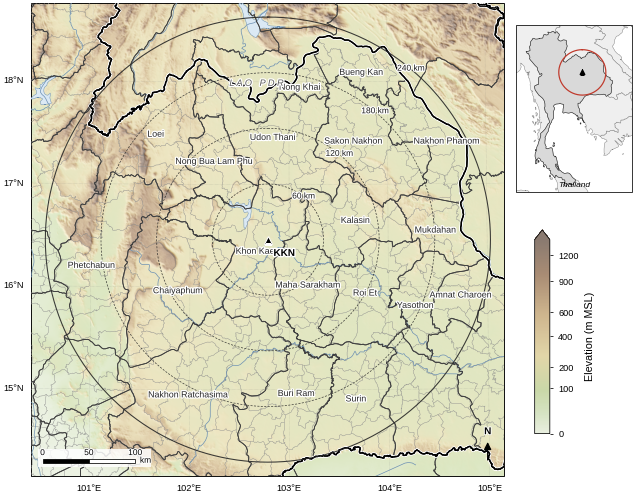

Saved: Fig02_qc_ppi_reasons.pdf (0.76 MB), Fig02_qc_ppi_reasons.png (0.67 MB)


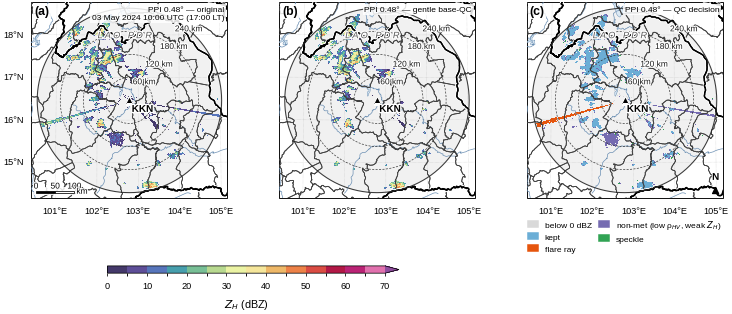

Saved: Fig03_polar_fields_6panel.pdf (1.51 MB), Fig03_polar_fields_6panel.png (1.51 MB)


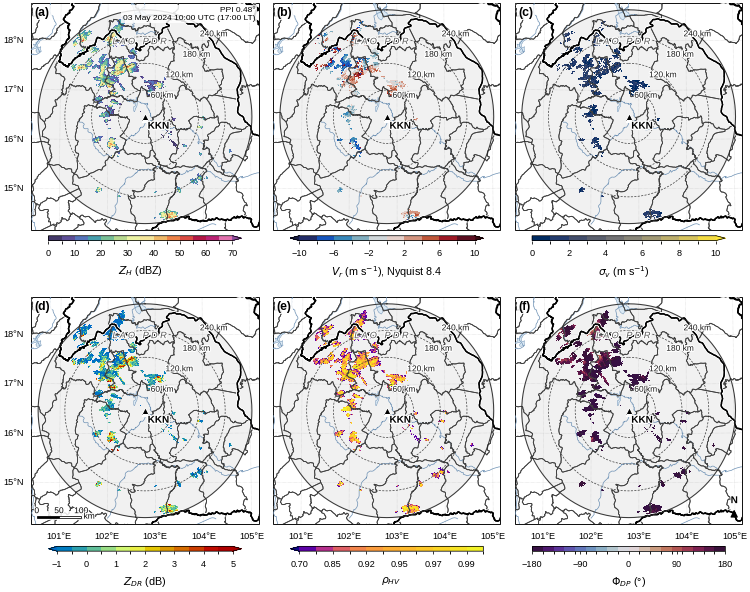

[PosixPath('/content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/2output/Github_Pysteps_Data_prepare/repo2_kkn_radar_dualpol/figures/Fig03_polar_fields_6panel.pdf'),
 PosixPath('/content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/2output/Github_Pysteps_Data_prepare/repo2_kkn_radar_dualpol/figures/Fig03_polar_fields_6panel.png')]

In [10]:
LAYERS = prepare_layers(RADAR_INFO["lon"], RADAR_INFO["lat"])
TERRAIN = prepare_terrain(RADAR_INFO["lon"], RADAR_INFO["lat"])
plot_study_area(LAYERS, TERRAIN)
plot_qc_reasons(radar, qc, SINGLE_TIME, sweep=PLOT_SWEEP)
plot_polar_six(radar_lean, SINGLE_TIME, sweep=PLOT_SWEEP)

---
# BATCH — ทั้งวัน
## C1. ประมวลผลทุก volume → `_work/repo2_polar/polar_all/`

In [11]:
def process_one_volume(raw_file, time_tag, isotherms):
    out_nc = WORK_DIR / "polar_all" / f"{RADAR_NAME}_{time_tag}_polar.nc"
    if out_nc.exists() and SKIP_EXISTING:
        r = pyart.io.read_cfradial(str(out_nc))
        z = np.ma.filled(r.fields["reflectivity_qc"]["data"].astype(float), np.nan)
        return {"time_tag": time_tag, "status": "skipped_existing", "nc": str(out_nc),
                "size_MB": out_nc.stat().st_size / 1e6, **sweep_echo_stats(r, z)}
    rdr = read_radar_magic(raw_file, verbose=False)
    flds = detect_fields(rdr)
    q = gentle_base_qc(rdr, flds, verbose=False)
    write_lean_polar(rdr, flds, q, out_nc, isotherms)
    return {"time_tag": time_tag, "status": "success", "nc": str(out_nc),
            "size_MB": out_nc.stat().st_size / 1e6, "nyquist": get_nyquist(rdr),
            **q["counts"], **sweep_echo_stats(rdr, q["reflectivity_qc"])}


set_pub_style()
inventory = build_inventory()
todo = inventory[inventory["exists"]]
if MAX_VOLUMES:
    todo = todo.head(MAX_VOLUMES)
ISOTHERMS = sounding_isotherms(SOUNDING_FILE)
print(f"Processing {len(todo)} volumes; missing slots: {int((~inventory['exists']).sum())}")

status = []
t_start = datetime.datetime.now()
for i, r in enumerate(todo.itertuples(), 1):
    try:
        res = process_one_volume(r.raw_file, r.time_tag, ISOTHERMS)
    except Exception as e:
        res = {"time_tag": r.time_tag, "status": "failed", "error": repr(e)}
        with open(WORK_DIR / "logs" / f"{r.time_tag}_error.log", "w") as f:
            f.write(traceback.format_exc())
    status.append(res)
    print(f"[{i:3d}/{len(todo)}] {r.time_tag} {res['status']}"
          + (f"  {res.get('size_MB', 0):.2f} MB" if "size_MB" in res else ""))
status = pd.DataFrame(status)
status.to_csv(WORK_DIR / "logs" / f"{RADAR_NAME}_{CASE_DATE}_batch_status.csv", index=False)
print(status["status"].value_counts().to_string(),
      f"\nelapsed: {(datetime.datetime.now()-t_start).total_seconds()/60:.1f} min")
if "size_MB" in status:
    print(f"lean file size: median {status['size_MB'].median():.2f} MB, max {status['size_MB'].max():.2f} MB")

Processing 92 volumes; missing slots: 4
[  1/92] 20240503_0000 success  0.21 MB
[  2/92] 20240503_0015 success  0.21 MB
[  3/92] 20240503_0030 success  0.20 MB
[  4/92] 20240503_0045 success  0.21 MB
[  5/92] 20240503_0100 success  0.20 MB
[  6/92] 20240503_0115 success  0.21 MB
[  7/92] 20240503_0130 success  0.21 MB
[  8/92] 20240503_0145 success  0.21 MB
[  9/92] 20240503_0200 success  0.22 MB
[ 10/92] 20240503_0215 success  0.22 MB
[ 11/92] 20240503_0230 success  0.23 MB
[ 12/92] 20240503_0245 success  0.23 MB
[ 13/92] 20240503_0300 success  0.23 MB
[ 14/92] 20240503_0315 success  0.23 MB
[ 15/92] 20240503_0330 success  0.20 MB
[ 16/92] 20240503_0345 success  0.20 MB
[ 17/92] 20240503_0500 success  0.23 MB
[ 18/92] 20240503_0515 success  0.24 MB
[ 19/92] 20240503_0530 success  0.26 MB
[ 20/92] 20240503_0545 success  0.27 MB
[ 21/92] 20240503_0600 success  0.31 MB
[ 22/92] 20240503_0615 success  0.34 MB
[ 23/92] 20240503_0630 success  0.39 MB
[ 24/92] 20240503_0645 success  0.44 MB


## C2. เลือกช่วงพีคของพายุ → คัดลอกเข้า `data/` ของ repo + sounding

In [12]:
stats = inventory[["time_tag", "time_utc", "exists"]].rename(columns={"exists": "available"})
stats = stats.merge(status.drop(columns=["status"], errors="ignore"), on="time_tag", how="left")
stats["available"] = stats["available"] & stats["nc"].notna()
key = f"area_ge{int(PEAK_DBZ)}_km2_sweep0"

if REPO2_TIMES:
    selected = list(REPO2_TIMES)
else:
    s = stats[key].where(stats["available"]).fillna(0.0).values
    n = min(PEAK_N_VOLUMES, int(stats["available"].sum()))
    win = np.convolve(s, np.ones(n), mode="valid")
    i0 = int(np.argmax(win))
    selected = [t for t, a in zip(stats["time_tag"].iloc[i0:i0 + n], stats["available"].iloc[i0:i0 + n]) if a]
print("Volumes copied to repo:", selected)

for old in POLAR_DIR.glob("*.nc"):
    old.unlink()
total = 0.0
for tag in selected:
    src = WORK_DIR / "polar_all" / f"{RADAR_NAME}_{tag}_polar.nc"
    dst = POLAR_DIR / src.name
    shutil.copy2(src, dst)
    total += dst.stat().st_size / 1e6
print(f"Repo polar data: {len(selected)} files, {total:.1f} MB")
if Path(SOUNDING_FILE).exists():
    shutil.copy2(SOUNDING_FILE, SOUNDING_DIR / Path(SOUNDING_FILE).name)
    print("Copied sounding:", Path(SOUNDING_FILE).name)
stats.drop(columns=["nc"]).to_csv(DATA_DIR / f"{RADAR_NAME}_{CASE_DATE}_volume_stats.csv", index=False)
inventory.to_csv(DATA_DIR / f"{RADAR_NAME}_{CASE_DATE}_inventory.csv", index=False)

Volumes copied to repo: ['20240503_0900', '20240503_0915', '20240503_0930', '20240503_0945', '20240503_1000', '20240503_1015', '20240503_1030', '20240503_1045']
Repo polar data: 8 files, 5.2 MB
Copied sounding: sounding_48431_2024-05-03_00Z.csv


## C3. ภาพอนุกรมเวลา และ manifest.json

Saved: Fig04_echo_area_timeseries.pdf (0.03 MB), Fig04_echo_area_timeseries.png (0.12 MB)


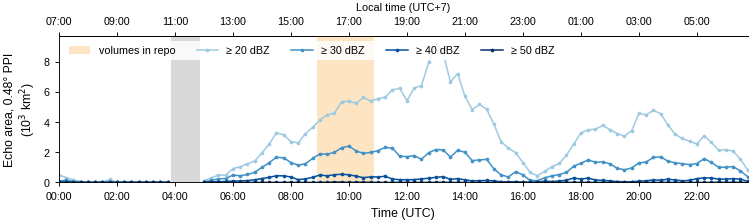

Files in repo folder:
  data/KKN_20240503/KKN_20240503_inventory.csv  0.01 MB
  data/KKN_20240503/KKN_20240503_volume_stats.csv  0.02 MB
  data/KKN_20240503/manifest.json  0.00 MB
  data/KKN_20240503/polar/KKN_20240503_0900_polar.nc  0.71 MB
  data/KKN_20240503/polar/KKN_20240503_0915_polar.nc  0.71 MB
  data/KKN_20240503/polar/KKN_20240503_0930_polar.nc  0.66 MB
  data/KKN_20240503/polar/KKN_20240503_0945_polar.nc  0.65 MB
  data/KKN_20240503/polar/KKN_20240503_1000_polar.nc  0.63 MB
  data/KKN_20240503/polar/KKN_20240503_1015_polar.nc  0.60 MB
  data/KKN_20240503/polar/KKN_20240503_1030_polar.nc  0.61 MB
  data/KKN_20240503/polar/KKN_20240503_1045_polar.nc  0.60 MB
  data/basemap/boundaries_KKN_255km.gpkg  2.60 MB
  data/basemap/terrain_KKN_aeqd_600m.nc  0.73 MB
  data/sounding/sounding_48431_2024-05-03_00Z.csv  0.01 MB
  figures/Fig01_study_area.pdf  3.14 MB
  figures/Fig01_study_area.png  2.46 MB
  figures/Fig02_qc_ppi_reasons.pdf  0.76 MB
  figures/Fig02_qc_ppi_reasons.png  0.67 M

In [13]:
LAYERS = prepare_layers(RADAR_INFO["lon"], RADAR_INFO["lat"]) if "LAYERS" not in globals() else LAYERS
plot_polar_timeseries(stats, selected)

manifest = {
    "dataset": f"{RADAR_NAME}_{CASE_DATE} lean polar volumes",
    "processing_code": PREP_VERSION,
    "notebook": "00_prepare_polar_for_doppler_pytda_hid.ipynb",
    "created_utc": f"{datetime.datetime.utcnow():%Y-%m-%dT%H:%M:%SZ}",
    "radar": RADAR_NAME, "case_date_utc": CASE_DATE,
    "files_in_repo": [f"polar/{RADAR_NAME}_{t}_polar.nc" for t in selected],
    "all_volumes_processed": int((status["status"] != "failed").sum()),
    "missing_slots": inventory.loc[~inventory["exists"], "time_tag"].tolist(),
    "failed": status.loc[status["status"] == "failed", "time_tag"].tolist(),
    "fields": {k: {"scale": v[2], "base": v[1]} for k, v in POLAR_SPECS.items()},
    "qc_flag_bits": QC_BITS,
    "nyquist_velocity_m_s": float(np.nanmedian(status["nyquist"])) if "nyquist" in status else None,
    "sounding": Path(SOUNDING_FILE).name, "isotherms_m_msl": ISOTHERMS,
    "qc_thresholds": {k: globals()[k] for k in [
        "ZH_ECHO_FLOOR_DBZ", "NONMET_RHOHV_MAX", "NONMET_ZH_MAX_DBZ", "SPECKLE_MIN_GATES",
        "FLARE_MIN_LEN_KM", "FLARE_ZH_MIN_DBZ", "FLARE_RHOHV_MEAN_MAX", "FLARE_VELVALID_MAX",
        "FLARE_PROTECT_DBZ", "FLARE_PROTECT_FRAC", "SW_MAX", "QC_SD_PHIDP_W", "QC_SD_PHIDP_MAX"]},
    "basemap_sources": {"boundaries": "geoBoundaries gbOpen (CC BY 4.0), https://www.geoboundaries.org",
                        "terrain": "AWS Open Data Terrain Tiles (Mapzen); SRTM/GMTED2010/ETOPO1",
                        "water": "Natural Earth (public domain)"},
    "data_credit": "Radar data: Thai Meteorological Department (TMD)",
}
with open(DATA_DIR / "manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False, default=str)

print("Files in repo folder:")
for p in sorted(REPO_DIR.rglob("*")):
    if p.is_file():
        mb = p.stat().st_size / 1e6
        print(f"  {p.relative_to(REPO_DIR)}  {mb:.2f} MB" + ("  <-- > 25 MB" if mb > 25 else ""))